# Progressive chess outcome prediction

**CA6001 — AI Algorithms Fundamentals & Application**  
**Data:** [Chess Game Dataset (Lichess), Kaggle](https://www.kaggle.com/datasets/datasnaek/chess)

## Research question

How accurately can the three-class result of a chess game (`black`, `draw`, `white`) be predicted before play, and how quickly does predictive performance improve as moves become available?

This notebook follows one compact, interpretable modelling line:

1. Download, inspect, clean, and split games.
2. Establish a pre-match baseline from ratings, rated status, and time control.
3. Train one **joint in-game model** that receives the pre-match features together with four Stockfish indicators (`score_cp`, `score_mate`, `wdl_wins`, and `wdl_draws`) and three transparent manual features (`ply`, `material_total`, and `material_diff`).
4. Compare the joint tabular model with a supervised CNN that receives the board, pre-match features, and current ply. The CNN uses neither Stockfish supervision nor reinforcement learning.
5. Evaluate the selected model retrospectively at 10%, 25%, 50%, 75%, and 100% of each test game.

> **Leakage boundary.** Final length and percentage progress are never model inputs. Training and validation positions are sampled at fixed ply counts. Percentages are used only to locate reporting positions in the untouched test set. Stockfish and manual features are calculated from the current position only, and all scores are oriented from White's perspective.

In [1]:
from __future__ import annotations

import hashlib
import io
import os
import random
import urllib.request
import warnings
import zipfile
import tarfile
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import chess
import chess.engine
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    log_loss,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

SEED = 6001
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print({
    "python_seed": SEED,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "python_chess": chess.__version__,
    "torch": torch.__version__,
    "device": str(DEVICE),
})

{'python_seed': 6001, 'pandas': '3.1.0', 'scikit_learn': '1.9.1', 'python_chess': '1.11.2', 'torch': '2.14.1+cpu', 'device': 'cpu'}


## 1. Acquire the source data

The public Kaggle API endpoint does not require credentials for this dataset. The cell is idempotent: it downloads only when `data/games.csv` is absent, verifies that the archive contains the expected member, writes to a temporary file, and atomically replaces the destination. The printed SHA-256 digest makes the exact input auditable.

In [2]:
DATA_URL = "https://www.kaggle.com/api/v1/datasets/download/datasnaek/chess"
STOCKFISH_URL = "https://github.com/official-stockfish/Stockfish/releases/download/sf_19/stockfish-linux-x86-64-universal.tar.gz"
STOCKFISH_ARCHIVE_SHA256 = "0f83d24cc46d2c66c60f16001af5444873bc112b7d028594513426894c12da19"
DATA_DIR = Path("data")
CSV_PATH = DATA_DIR / "games.csv"
DEFAULT_STOCKFISH_PATH = Path("vendor/stockfish/stockfish-linux-x86-64-universal")


def acquire_data(url: str = DATA_URL, destination: Path = CSV_PATH) -> Path:
    """Download and atomically materialize the public Kaggle CSV when needed."""
    if destination.exists():
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    with urllib.request.urlopen(url, timeout=120) as response:
        archive_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        if "games.csv" not in archive.namelist():
            raise RuntimeError("The downloaded archive does not contain games.csv.")
        payload = archive.read("games.csv")
    temporary = destination.with_suffix(".csv.tmp")
    temporary.write_bytes(payload)
    temporary.replace(destination)
    return destination


def acquire_stockfish(destination: Path = DEFAULT_STOCKFISH_PATH) -> Path:
    """Acquire the pinned Stockfish 19 Linux binary or use STOCKFISH_EXECUTABLE."""
    configured = os.environ.get("STOCKFISH_EXECUTABLE")
    if configured:
        executable = Path(configured).expanduser()
        if not executable.exists():
            raise FileNotFoundError("STOCKFISH_EXECUTABLE does not exist.")
        return executable
    if destination.exists():
        return destination
    if os.name != "posix":
        raise RuntimeError("Set STOCKFISH_EXECUTABLE to a compatible Stockfish binary on this platform.")
    with urllib.request.urlopen(STOCKFISH_URL, timeout=180) as response:
        archive_bytes = response.read()
    digest = hashlib.sha256(archive_bytes).hexdigest()
    if digest != STOCKFISH_ARCHIVE_SHA256:
        raise RuntimeError("The Stockfish archive hash does not match the pinned release.")
    member_name = "stockfish/stockfish-linux-x86-64-universal"
    with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
        member = archive.getmember(member_name)
        source = archive.extractfile(member)
        if source is None:
            raise RuntimeError("The Stockfish executable is missing from the archive.")
        payload = source.read()
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(".tmp")
    temporary.write_bytes(payload)
    temporary.chmod(0o755)
    temporary.replace(destination)
    return destination


source_path = acquire_data()
stockfish_path = acquire_stockfish()
source_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
stockfish_hash = hashlib.sha256(stockfish_path.read_bytes()).hexdigest()
print(f"Dataset: {source_path.resolve()} ({source_path.stat().st_size / 1_000_000:.2f} MB)")
print(f"Dataset SHA-256: {source_hash}")
print(f"Stockfish: {stockfish_path.resolve()}")
print(f"Stockfish SHA-256: {stockfish_hash}")

Dataset: /home/gushucheng/Chess/data/games.csv (7.67 MB)
Dataset SHA-256: e7aadff104a610afb5403caf81c1461babecb0dc87760ff5eea7dc0e7a4a8129
Stockfish: /home/gushucheng/Chess/vendor/stockfish/stockfish-linux-x86-64-universal
Stockfish SHA-256: 0f83d24cc46d2c66c60f16001af5444873bc112b7d028594513426894c12da19


## 2. Initial inspection, cleaning, and data split

The target is genuinely multiclass. Macro-F1 is the primary selection metric because a high overall accuracy can conceal failure on the comparatively rare draw class; accuracy and multiclass log loss are reported alongside it. Duplicates are removed before splitting, and the split is stratified by outcome. A fixed random seed makes it reproducible.

In [3]:
raw = pd.read_csv(source_path)
print(f"Raw shape: {raw.shape}")
display(raw.head(3))

inspection = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100).round(2),
    "unique": raw.nunique(dropna=False),
})
display(inspection)
print(f"Duplicate game IDs: {raw['id'].duplicated().sum()}")
print("Outcome counts:")
display(raw["winner"].value_counts(dropna=False).to_frame("count"))

Raw shape: (20058, 16)


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3


,dtype,missing,missing_pct,unique
id,str,0,0.0,19113
rated,bool,0,0.0,2
created_at,float64,0,0.0,13151
last_move_at,float64,0,0.0,13186
turns,int64,0,0.0,211
victory_status,str,0,0.0,4
winner,str,0,0.0,3
increment_code,str,0,0.0,400
white_id,str,0,0.0,9438
white_rating,int64,0,0.0,1516


Duplicate game IDs: 945
Outcome counts:


,count
winner,
white,10001
black,9107
draw,950


In [4]:
VALID_WINNERS = {"black", "draw", "white"}
LABEL_TO_INT = {"black": 0, "draw": 1, "white": 2}
CLASS_NAMES = np.array(["black", "draw", "white"])


def clean_games(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Apply explicit quality rules and return clean rows plus an audit trail."""
    audit = {}
    work = frame.copy()
    audit["raw_rows"] = len(work)
    work = work.drop_duplicates(subset="id", keep="first")
    audit["duplicate_ids_removed"] = audit["raw_rows"] - len(work)

    valid_target = work["winner"].isin(VALID_WINNERS)
    valid_ratings = work["white_rating"].between(100, 4000) & work["black_rating"].between(100, 4000)
    valid_moves = work["moves"].fillna("").str.strip().ne("")
    parsed_time = work["increment_code"].astype(str).str.extract(r"^(\d+)\+(\d+)$").astype(float)
    valid_time = parsed_time.notna().all(axis=1)
    keep = valid_target & valid_ratings & valid_moves & valid_time
    audit["invalid_target_removed"] = int((~valid_target).sum())
    audit["invalid_rating_removed"] = int((~valid_ratings).sum())
    audit["empty_move_list_removed"] = int((~valid_moves).sum())
    audit["invalid_time_control_removed"] = int((~valid_time).sum())

    work = work.loc[keep].copy().reset_index(drop=True)
    parsed_time = parsed_time.loc[keep].reset_index(drop=True)
    work["base_minutes"] = parsed_time[0].astype(int)
    work["increment_seconds"] = parsed_time[1].astype(int)
    work["rated_int"] = work["rated"].astype(int)
    work["move_count"] = work["moves"].str.split().str.len()
    work["rating_diff"] = work["white_rating"] - work["black_rating"]
    work["rating_mean"] = (work["white_rating"] + work["black_rating"]) / 2
    work["rating_gap"] = work["rating_diff"].abs()
    work["log_base_minutes"] = np.log1p(work["base_minutes"])
    work["white_elo_expectation"] = 1 / (1 + 10 ** (-work["rating_diff"] / 400))
    work["target"] = work["winner"].map(LABEL_TO_INT).astype(int)
    audit["clean_rows"] = len(work)
    return work, pd.Series(audit, name="count")


games, cleaning_audit = clean_games(raw)
display(cleaning_audit.to_frame())
print(f"Clean shape: {games.shape}")
print("Declared turns minus tokenized SAN count:")
display((games["turns"] - games["move_count"]).value_counts().head().to_frame("games"))

,count
raw_rows,20058
duplicate_ids_removed,945
invalid_target_removed,0
invalid_rating_removed,0
empty_move_list_removed,0
invalid_time_control_removed,0
clean_rows,19113


Clean shape: (19113, 26)
Declared turns minus tokenized SAN count:


,games
0,19113


In [5]:
all_indices = np.arange(len(games))
train_idx, holdout_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=games["target"],
)
val_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=games.loc[holdout_idx, "target"],
)

split_by_index = np.full(len(games), "", dtype=object)
split_by_index[train_idx] = "train"
split_by_index[val_idx] = "validation"
split_by_index[test_idx] = "test"
games["split"] = split_by_index

assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert games["id"].is_unique

split_summary = (
    games.groupby(["split", "winner"], observed=True)
    .size()
    .unstack(fill_value=0)
    .assign(total=lambda x: x.sum(axis=1))
)
display(split_summary)

winner,black,draw,white,total
split,,,,
test,1302,133,1432,2867
train,6076,622,6681,13379
validation,1302,133,1432,2867


## 3. Pre-match statistics, correlation analysis, and visualisation

`opening_eco`, `opening_name`, and `opening_ply` are derived from moves and are therefore excluded from pre-match modelling. Player IDs are also excluded: memorising frequent players would weaken generalisation to unseen players. Game duration, final turn count, and termination status become known only after or during play and are outcome-leaking for the pre-match task.

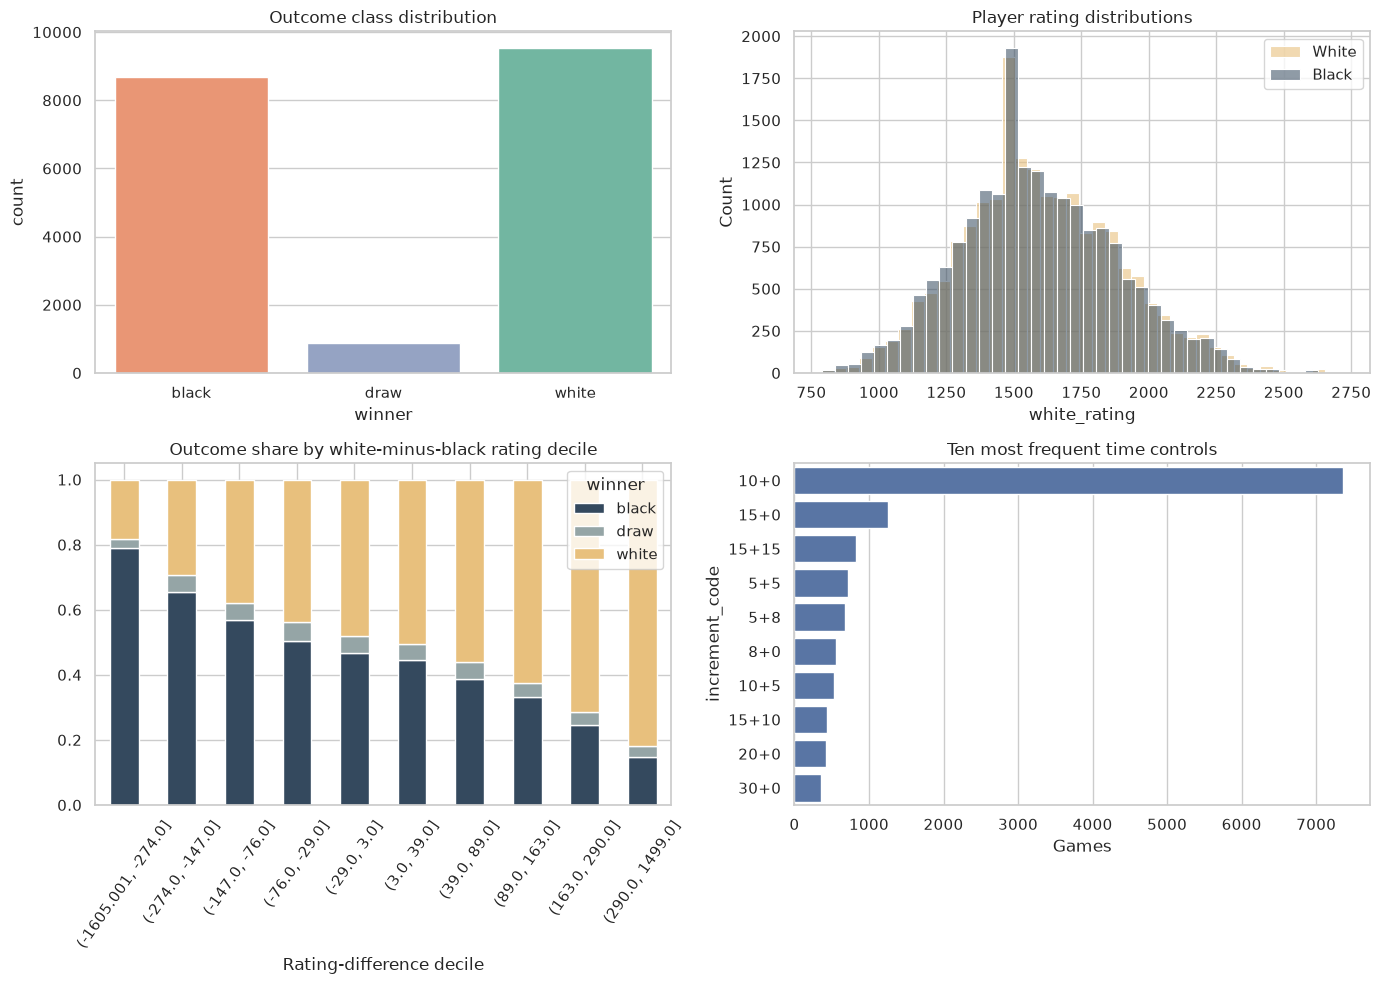

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=games, x="winner", order=CLASS_NAMES, ax=axes[0, 0], palette="Set2", hue="winner", legend=False)
axes[0, 0].set_title("Outcome class distribution")

sns.histplot(games["white_rating"], bins=40, color="#e8c07d", alpha=0.6, label="White", ax=axes[0, 1])
sns.histplot(games["black_rating"], bins=40, color="#34495e", alpha=0.55, label="Black", ax=axes[0, 1])
axes[0, 1].legend()
axes[0, 1].set_title("Player rating distributions")

rating_bins = pd.qcut(games["rating_diff"], q=10, duplicates="drop")
win_by_rating = pd.crosstab(rating_bins, games["winner"], normalize="index")
win_by_rating.plot(kind="bar", stacked=True, color=["#34495e", "#95a5a6", "#e8c07d"], ax=axes[1, 0])
axes[1, 0].set_title("Outcome share by white-minus-black rating decile")
axes[1, 0].set_xlabel("Rating-difference decile")
axes[1, 0].tick_params(axis="x", labelrotation=55)

top_controls = games["increment_code"].value_counts().head(10).index
sns.countplot(
    data=games[games["increment_code"].isin(top_controls)],
    y="increment_code",
    order=top_controls,
    ax=axes[1, 1],
    color="#4c72b0",
)
axes[1, 1].set_title("Ten most frequent time controls")
axes[1, 1].set_xlabel("Games")

plt.tight_layout()
fig.savefig(FIGURE_DIR / "01_eda_overview.png", dpi=300, bbox_inches="tight")
plt.show()

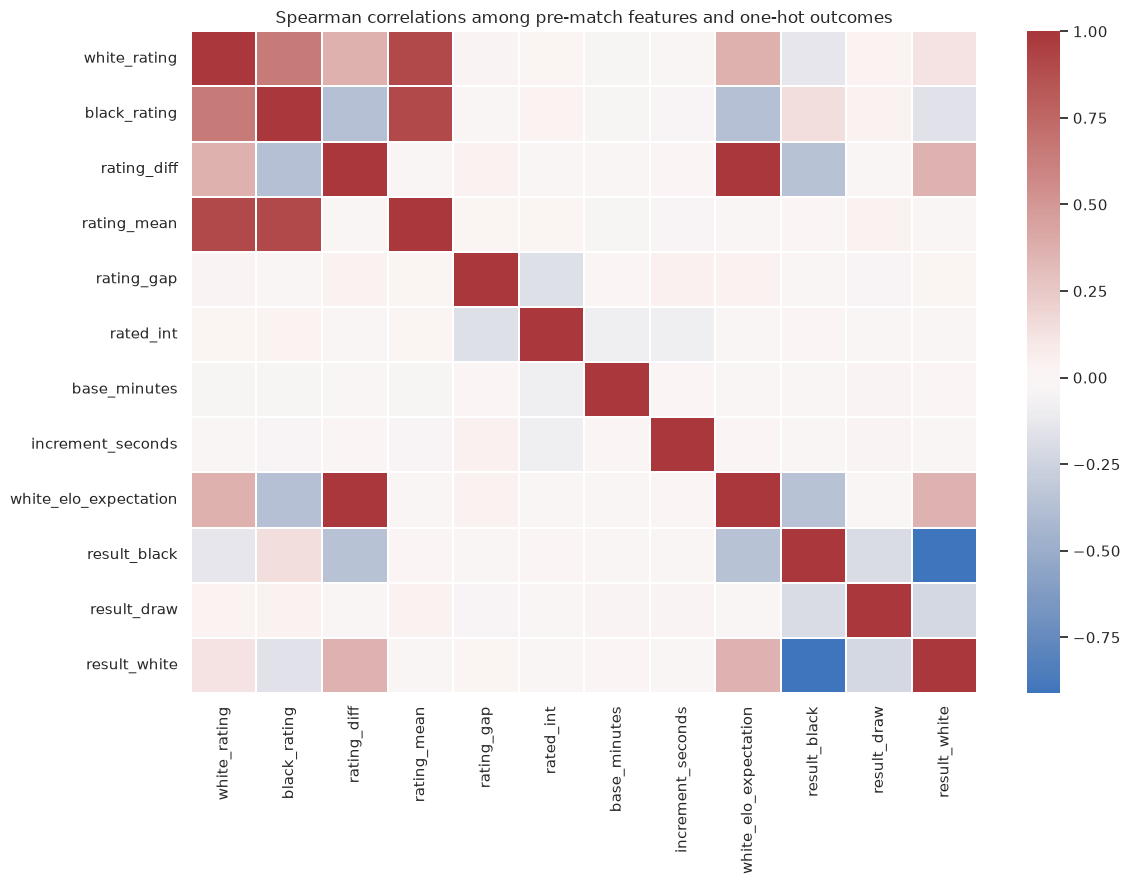

white_rating                 black_rating                 rating_diff  \
               mean  median     std         mean  median     std        mean   
winner                                                                         
black       1550.82  1527.0  282.50      1639.27  1610.0  289.45      -88.45   
draw        1649.32  1623.5  308.86      1642.19  1627.0  301.63        7.13   
white       1634.73  1603.0  288.76      1540.43  1517.0  281.71       94.30   

                      rating_gap                base_minutes                
       median     std       mean median     std         mean median    std  
winner                                                                      
black   -52.0  229.32     171.52  114.5  176.03        13.52   10.0  16.41  
draw     -2.5  210.33     144.33   93.5  153.08        16.59   10.0  24.38  
white    59.0  234.03     175.68  117.0  181.09        13.77   10.0  16.81

In [7]:
correlation_frame = games[[
    "white_rating", "black_rating", "rating_diff", "rating_mean", "rating_gap",
    "rated_int", "base_minutes", "increment_seconds", "white_elo_expectation",
]].copy()
outcome_dummies = pd.get_dummies(games["winner"], prefix="result", dtype=float)
corr = pd.concat([correlation_frame, outcome_dummies], axis=1).corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="vlag", center=0, square=False, linewidths=0.3)
plt.title("Spearman correlations among pre-match features and one-hot outcomes")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_prematch_correlations.png", dpi=300, bbox_inches="tight")
plt.show()

display(
    games.groupby("winner")[["white_rating", "black_rating", "rating_diff", "rating_gap", "base_minutes"]]
    .agg(["mean", "median", "std"])
    .round(2)
)

## 4. Pre-match models

Three levels are compared:

- majority-class dummy: a necessary sanity baseline;
- class-balanced multinomial logistic regression: a transparent linear AI model;
- histogram gradient boosting: a nonlinear tree ensemble in the same broad boosting family as XGBoost, chosen here because it is fast, supports missing-value-safe tabular learning, and is already maintained in scikit-learn.

Class-balanced fitting emphasises macro-F1 and gives draws meaningful influence. Model selection uses validation macro-F1 only; the test set is touched once after selection.

In [8]:
PREMATCH_FEATURES = [
    "white_rating", "black_rating", "rating_diff", "rating_mean", "rating_gap",
    "rated_int", "base_minutes", "increment_seconds", "log_base_minutes",
    "white_elo_expectation",
]


def metric_row(name: str, y_true: np.ndarray, probabilities: np.ndarray) -> dict:
    predictions = probabilities.argmax(axis=1)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "log_loss": log_loss(y_true, probabilities, labels=[0, 1, 2]),
    }


X_train_pre = games.loc[train_idx, PREMATCH_FEATURES]
y_train = games.loc[train_idx, "target"].to_numpy()
X_val_pre = games.loc[val_idx, PREMATCH_FEATURES]
y_val = games.loc[val_idx, "target"].to_numpy()
X_test_pre = games.loc[test_idx, PREMATCH_FEATURES]
y_test = games.loc[test_idx, "target"].to_numpy()

class_counts = np.bincount(y_train, minlength=3)
class_weights = len(y_train) / (3 * class_counts)
train_sample_weights = class_weights[y_train]

prematch_candidates = {
    "Majority dummy": DummyClassifier(strategy="prior"),
    "Balanced logistic regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2_000, class_weight="balanced", random_state=SEED)),
    ]),
    "Histogram gradient boosting": HistGradientBoostingClassifier(
        learning_rate=0.07,
        max_iter=250,
        max_leaf_nodes=23,
        l2_regularization=1.0,
        early_stopping=True,
        random_state=SEED,
    ),
}

validation_rows = []
for name, model in prematch_candidates.items():
    if name == "Histogram gradient boosting":
        model.fit(X_train_pre, y_train, sample_weight=train_sample_weights)
    else:
        model.fit(X_train_pre, y_train)
    validation_rows.append(metric_row(name, y_val, model.predict_proba(X_val_pre)))

prematch_validation = pd.DataFrame(validation_rows).sort_values("macro_f1", ascending=False)
display(prematch_validation.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

best_prematch_name = prematch_validation.iloc[0]["model"]
best_prematch = prematch_candidates[best_prematch_name]
prematch_test_proba = best_prematch.predict_proba(X_test_pre)
prematch_test_metrics = pd.DataFrame([metric_row(best_prematch_name, y_test, prematch_test_proba)])
print(f"Selected pre-match model: {best_prematch_name}")
display(prematch_test_metrics.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

,model,accuracy,macro_f1,log_loss
2,Histogram gradient boosting,0.497,0.400,0.987
1,Balanced logistic regression,0.473,0.393,1.025
0,Majority dummy,0.499,0.222,0.848


Selected pre-match model: Histogram gradient boosting


,model,accuracy,macro_f1,log_loss
0,Histogram gradient boosting,0.523,0.427,0.980


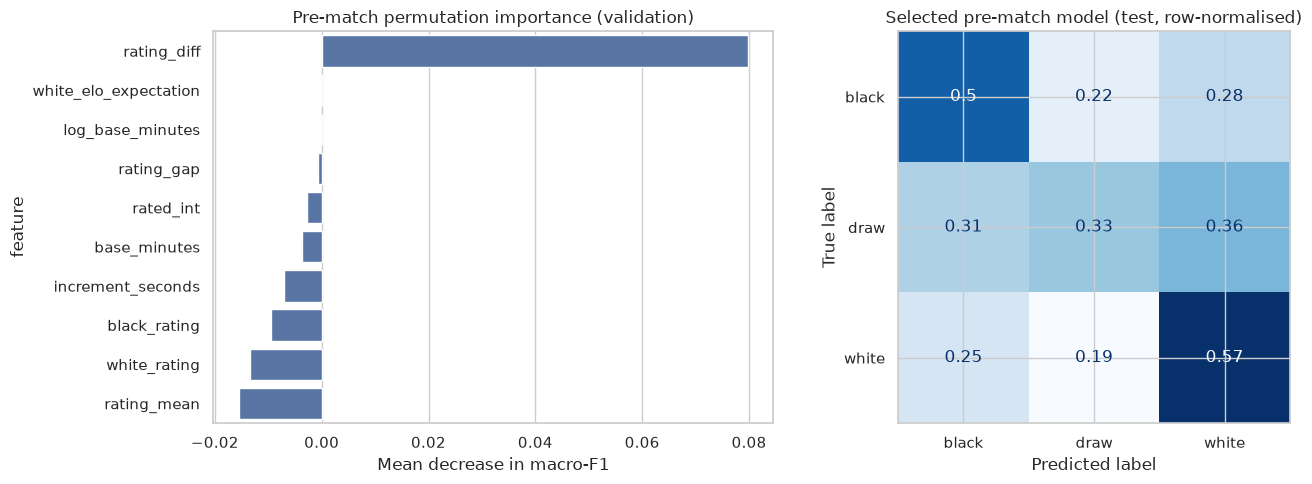

              precision    recall  f1-score   support

       black      0.619     0.496     0.551      1302
        draw      0.074     0.331     0.121       133
       white      0.659     0.566     0.609      1432

    accuracy                          0.523      2867
   macro avg      0.451     0.464     0.427      2867
weighted avg      0.614     0.523     0.560      2867



In [9]:
importance = permutation_importance(
    best_prematch,
    X_val_pre,
    y_val,
    scoring="f1_macro",
    n_repeats=8,
    random_state=SEED,
    n_jobs=-1,
)
importance_frame = pd.DataFrame({
    "feature": PREMATCH_FEATURES,
    "mean_macro_f1_drop": importance.importances_mean,
    "std": importance.importances_std,
}).sort_values("mean_macro_f1_drop", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=importance_frame, x="mean_macro_f1_drop", y="feature", color="#4c72b0", ax=axes[0])
axes[0].set_title("Pre-match permutation importance (validation)")
axes[0].set_xlabel("Mean decrease in macro-F1")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    prematch_test_proba.argmax(axis=1),
    display_labels=CLASS_NAMES,
    normalize="true",
    cmap="Blues",
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title("Selected pre-match model (test, row-normalised)")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "03_prematch_importance_confusion.png", dpi=300, bbox_inches="tight")
plt.show()

print(classification_report(y_test, prematch_test_proba.argmax(axis=1), target_names=CLASS_NAMES, digits=3, zero_division=0))

## 5. Joint in-game modelling

Training and validation positions are sampled at fixed ply counts (ply 4, then every 8 plies through 160). Test positions alone are located by retrospective percentage checkpoints.

The joint tabular model deliberately uses a small feature set:

- **Pre-match:** the same rating, rated-status, and time-control features used by the pre-match baseline.
- **Stockfish:** centipawn score, mate distance, WDL wins, and WDL draws.
- **Manual:** current ply, total non-king material, and White-minus-Black material difference.

Stockfish scores and material difference are always from White's perspective. Search-control statistics and internal engine strategy terms are recorded neither as features nor as targets.

In [10]:
TRAINING_PLIES = (4, *range(8, 161, 8))
EVALUATION_FRACTIONS = (0.10, 0.25, 0.50, 0.75, 1.00)
PLY_SCALE = 100.0
PIECE_VALUES = {
    chess.PAWN: 1,
    chess.KNIGHT: 3,
    chess.BISHOP: 3,
    chess.ROOK: 5,
    chess.QUEEN: 9,
}


def board_features(board: chess.Board, ply: int) -> dict[str, float]:
    """Return the three intentionally minimal manual position features."""
    white_material = sum(
        value * len(board.pieces(piece_type, chess.WHITE))
        for piece_type, value in PIECE_VALUES.items()
    )
    black_material = sum(
        value * len(board.pieces(piece_type, chess.BLACK))
        for piece_type, value in PIECE_VALUES.items()
    )
    return {
        "ply": ply,
        "material_total": white_material + black_material,
        "material_diff": white_material - black_material,
    }


def board_planes(board: chess.Board) -> np.ndarray:
    """Encode a board as 12 piece, 1 turn, and 4 castling-right planes."""
    planes = np.zeros((17, 8, 8), dtype=np.uint8)
    for square, piece in board.piece_map().items():
        offset = 0 if piece.color == chess.WHITE else 6
        channel = offset + piece.piece_type - 1
        row = 7 - chess.square_rank(square)
        column = chess.square_file(square)
        planes[channel, row, column] = 1
    planes[12, :, :] = int(board.turn == chess.WHITE)
    planes[13, :, :] = int(board.has_kingside_castling_rights(chess.WHITE))
    planes[14, :, :] = int(board.has_queenside_castling_rights(chess.WHITE))
    planes[15, :, :] = int(board.has_kingside_castling_rights(chess.BLACK))
    planes[16, :, :] = int(board.has_queenside_castling_rights(chess.BLACK))
    return planes

In [11]:
def extract_snapshots(frame: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray, pd.DataFrame]:
    """Replay games and extract fixed-ply modelling or percentage evaluation snapshots."""
    records, tensors, failures = [], [], []
    for game_index, row in frame.iterrows():
        record_start, tensor_start = len(records), len(tensors)
        tokens = row["moves"].split()
        if row["split"] == "test":
            targets = {
                max(1, min(len(tokens), int(round(len(tokens) * fraction)))): ("percentage_evaluation", fraction)
                for fraction in EVALUATION_FRACTIONS
            }
        else:
            targets = {
                ply: ("fixed_ply_modelling", -1.0)
                for ply in TRAINING_PLIES
                if ply <= len(tokens)
            }

        board = chess.Board()
        try:
            for ply, san in enumerate(tokens, start=1):
                board.push_san(san)
                if ply in targets:
                    sampling_scheme, checkpoint = targets[ply]
                    record = {
                        "game_index": game_index,
                        "game_id": row["id"],
                        "split": row["split"],
                        "target": row["target"],
                        "sampling_scheme": sampling_scheme,
                        "checkpoint": checkpoint,
                        "fen": board.fen(),
                    }
                    record.update(board_features(board, ply))
                    records.append(record)
                    tensors.append(board_planes(board))
        except ValueError as error:
            failures.append({"game_index": game_index, "game_id": row["id"], "reason": str(error)})
            del records[record_start:]
            del tensors[tensor_start:]

    snapshot_frame = pd.DataFrame.from_records(records)
    board_tensor = np.stack(tensors) if tensors else np.empty((0, 17, 8, 8), dtype=np.uint8)
    return snapshot_frame, board_tensor, pd.DataFrame(failures)


snapshots, boards, parse_failures = extract_snapshots(games)
assert len(snapshots) == len(boards)
assert not snapshots.isna().any().any()
print(f"Snapshots: {len(snapshots):,}; board tensor: {boards.shape}; memory: {boards.nbytes / 1_000_000:.1f} MB")
print(f"Games with SAN parsing failures: {len(parse_failures)}")
display(snapshots.groupby(["split", "sampling_scheme"]).size().to_frame("snapshots"))
display(snapshots.loc[snapshots["split"].eq("test")].groupby("checkpoint").size().rename("test_games").to_frame())

Snapshots: 146,111; board tensor: (146111, 17, 8, 8); memory: 159.0 MB
Games with SAN parsing failures: 0


,,snapshots
split,sampling_scheme,
test,percentage_evaluation,14179
train,fixed_ply_modelling,108534
validation,fixed_ply_modelling,23398


,test_games
checkpoint,
0.10,2803
0.25,2830
0.50,2849
0.75,2830
1.00,2867


### 5.1 Stockfish analysis and cache

Stockfish 19 analyses each unique snapshot with a fixed 1,000-node budget, one engine thread, and `UCI_ShowWDL=True`. Only four outputs enter the model: `score_cp`, `score_mate`, `wdl_wins`, and `wdl_draws`. The cache key includes the position, game/ply identity, engine binary hash, and node budget. Cache writes deduplicate by this stable key and atomically replace the CSV, so rerunning the notebook is idempotent.

In [12]:
STOCKFISH_NODES = 1_000
STOCKFISH_WORKERS = min(8, max(1, (os.cpu_count() or 2) // 2))
STOCKFISH_CACHE = DATA_DIR / "stockfish_features.csv"
STOCKFISH_FEATURES = ["score_cp", "score_mate", "wdl_wins", "wdl_draws"]
MANUAL_FEATURES = ["ply", "material_total", "material_diff"]
engine_config_id = f"sf19-{stockfish_hash[:12]}-nodes{STOCKFISH_NODES}"

snapshots["stockfish_key"] = [
    hashlib.sha256(f"{game_id}|{ply}|{fen}|{engine_config_id}".encode()).hexdigest()
    for game_id, ply, fen in zip(snapshots["game_id"], snapshots["ply"], snapshots["fen"])
]


def analyse_stockfish_chunk(records: list[dict]) -> list[dict]:
    """Analyse one chunk with a dedicated engine process."""
    engine = chess.engine.SimpleEngine.popen_uci(str(stockfish_path))
    engine.configure({"Threads": 1, "Hash": 16, "UCI_ShowWDL": True})
    output = []
    try:
        for record in records:
            board = chess.Board(record["fen"])
            info = engine.analyse(
                board,
                chess.engine.Limit(nodes=STOCKFISH_NODES),
                info=chess.engine.INFO_SCORE,
            )
            score = info["score"].pov(chess.WHITE)
            if "wdl" in info:
                wdl = info["wdl"].pov(chess.WHITE)
                wdl_wins, wdl_draws = wdl.wins, wdl.draws
            else:
                outcome = board.outcome(claim_draw=True)
                if outcome is None:
                    raise RuntimeError("Stockfish omitted WDL for a non-terminal position.")
                wdl_wins = 1000 if outcome.winner == chess.WHITE else 0
                wdl_draws = 1000 if outcome.winner is None else 0
            output.append({
                "stockfish_key": record["stockfish_key"],
                "score_cp": score.score(),
                "score_mate": score.mate(),
                "wdl_wins": wdl_wins,
                "wdl_draws": wdl_draws,
                "engine_config": engine_config_id,
            })
    finally:
        engine.quit()
    return output


cache_columns = ["stockfish_key", *STOCKFISH_FEATURES, "engine_config"]
if STOCKFISH_CACHE.exists():
    stockfish_cache = pd.read_csv(STOCKFISH_CACHE)
    stockfish_cache = stockfish_cache.loc[stockfish_cache["engine_config"].eq(engine_config_id), cache_columns]
    stockfish_cache = stockfish_cache.drop_duplicates("stockfish_key", keep="last")
else:
    stockfish_cache = pd.DataFrame(columns=cache_columns)

known_keys = set(stockfish_cache["stockfish_key"])
pending = snapshots.loc[~snapshots["stockfish_key"].isin(known_keys), ["stockfish_key", "fen"]]
print(f"Cached positions: {len(stockfish_cache):,}; pending positions: {len(pending):,}")

if len(pending):
    chunks = [
        pending.iloc[row_indices].to_dict("records")
        for row_indices in np.array_split(np.arange(len(pending)), STOCKFISH_WORKERS)
        if len(row_indices)
    ]
    new_records = []
    with ThreadPoolExecutor(max_workers=len(chunks)) as executor:
        futures = [executor.submit(analyse_stockfish_chunk, chunk) for chunk in chunks]
        for future in as_completed(futures):
            new_records.extend(future.result())
            print(f"Analysed {len(new_records):,}/{len(pending):,} pending positions")
    stockfish_cache = pd.concat([stockfish_cache, pd.DataFrame(new_records)], ignore_index=True)
    stockfish_cache = stockfish_cache.drop_duplicates("stockfish_key", keep="last")
    temporary = STOCKFISH_CACHE.with_suffix(".csv.tmp")
    stockfish_cache.to_csv(temporary, index=False)
    temporary.replace(STOCKFISH_CACHE)

feature_maps = stockfish_cache.set_index("stockfish_key")[STOCKFISH_FEATURES]
for feature in STOCKFISH_FEATURES:
    snapshots[feature] = snapshots["stockfish_key"].map(feature_maps[feature])

assert snapshots[["wdl_wins", "wdl_draws"]].notna().all().all()
assert snapshots[["score_cp", "score_mate"]].notna().any(axis=1).all()

for feature in PREMATCH_FEATURES:
    snapshots[feature] = snapshots["game_index"].map(games[feature])

snapshot_masks = {name: snapshots["split"].eq(name).to_numpy() for name in ("train", "validation", "test")}
y_snapshot = snapshots["target"].to_numpy()
train_game_counts = snapshots.loc[snapshot_masks["train"]].groupby("game_index").size()
train_game_targets = games.loc[train_idx, "target"].to_numpy()
class_counts = np.bincount(train_game_targets, minlength=3)
class_weights = len(train_game_targets) / (3 * class_counts)
snapshot_weights = np.ones(len(snapshots), dtype=np.float32)
train_rows = snapshots.loc[snapshot_masks["train"]]
snapshot_weights[snapshot_masks["train"]] = [
    class_weights[target] / train_game_counts.loc[game_index]
    for target, game_index in zip(train_rows["target"], train_rows["game_index"])
]
snapshot_weights[snapshot_masks["train"]] /= snapshot_weights[snapshot_masks["train"]].mean()

TABULAR_SPECS = {
    "Joint metadata + manual": PREMATCH_FEATURES + MANUAL_FEATURES,
    "Joint metadata + manual + Stockfish": PREMATCH_FEATURES + MANUAL_FEATURES + STOCKFISH_FEATURES,
}
tabular_models, tabular_val_probas, tabular_test_probas, tabular_validation_rows = {}, {}, {}, []
for name, features in TABULAR_SPECS.items():
    model = HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=240,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        early_stopping=True,
        random_state=SEED,
    )
    model.fit(
        snapshots.loc[snapshot_masks["train"], features],
        y_snapshot[snapshot_masks["train"]],
        sample_weight=snapshot_weights[snapshot_masks["train"]],
    )
    val_proba = model.predict_proba(snapshots.loc[snapshot_masks["validation"], features])
    test_proba = model.predict_proba(snapshots.loc[snapshot_masks["test"], features])
    tabular_models[name] = model
    tabular_val_probas[name] = val_proba
    tabular_test_probas[name] = test_proba
    tabular_validation_rows.append(metric_row(name, y_snapshot[snapshot_masks["validation"]], val_proba))

tabular_validation = pd.DataFrame(tabular_validation_rows).sort_values("macro_f1", ascending=False)
display(tabular_validation.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))
best_tabular_name = tabular_validation.iloc[0]["model"]
best_tabular = tabular_models[best_tabular_name]
best_tabular_features = TABULAR_SPECS[best_tabular_name]
print(f"Selected tabular model: {best_tabular_name}")

Cached positions: 146,111; pending positions: 0


,model,accuracy,macro_f1,log_loss
1,Joint metadata + manual + Stockfish,0.651,0.524,0.788
0,Joint metadata + manual,0.613,0.484,0.844


Selected tabular model: Joint metadata + manual + Stockfish


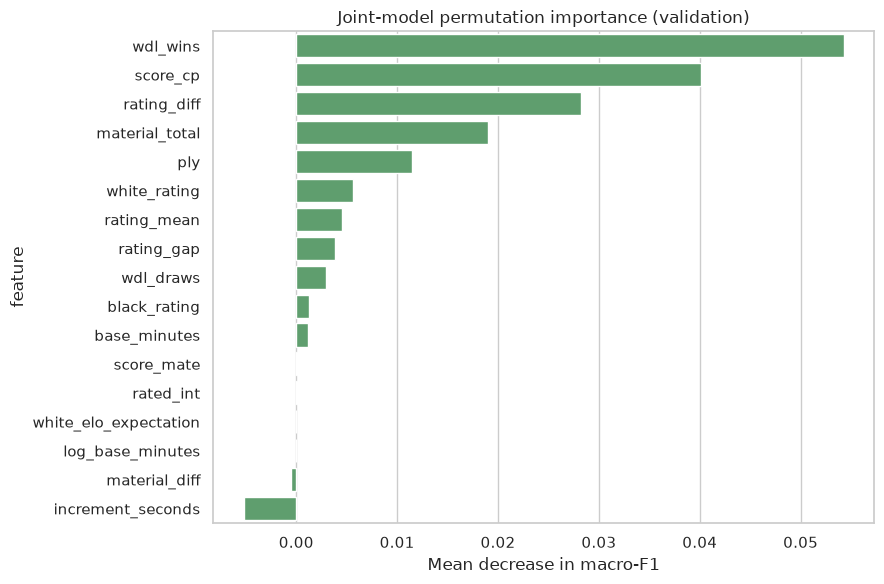

In [13]:
joint_importance = permutation_importance(
    best_tabular,
    snapshots.loc[snapshot_masks["validation"], best_tabular_features],
    y_snapshot[snapshot_masks["validation"]],
    scoring="f1_macro",
    n_repeats=5,
    random_state=SEED,
    n_jobs=-1,
)
joint_importance_frame = pd.DataFrame({
    "feature": best_tabular_features,
    "mean_macro_f1_drop": joint_importance.importances_mean,
    "std": joint_importance.importances_std,
}).sort_values("mean_macro_f1_drop", ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=joint_importance_frame, x="mean_macro_f1_drop", y="feature", color="#55a868")
plt.title("Joint-model permutation importance (validation)")
plt.xlabel("Mean decrease in macro-F1")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_joint_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Supervised CNN comparison

The CNN is intentionally independent of Stockfish. Its 17 binary planes contain 12 colour-specific piece maps, side to move, and four castling rights. A small metadata branch receives the pre-match features and current ply; it is concatenated with the convolutional board embedding before three-class classification. Training uses only the recorded game result, weighted cross-entropy, and validation early stopping—no engine targets, policy head, self-play, or reinforcement learning.

Epoch 01 | train loss 0.9878 | val macro-F1 0.4099


Epoch 02 | train loss 0.9476 | val macro-F1 0.4290


Epoch 03 | train loss 0.9299 | val macro-F1 0.4802


Epoch 04 | train loss 0.9175 | val macro-F1 0.4697


Epoch 05 | train loss 0.9067 | val macro-F1 0.4645


...

Epoch 08 | train loss 0.8653 | val macro-F1 0.4626


Epoch 09 | train loss 0.8503 | val macro-F1 0.4681


Epoch 10 | train loss 0.8366 | val macro-F1 0.4787


Epoch 11 | train loss 0.8223 | val macro-F1 0.4498
Early stopping triggered.


,model,accuracy,macro_f1,log_loss
0,Joint CNN (validation),0.591,0.487,0.888
1,Joint CNN (test),0.610,0.478,0.898


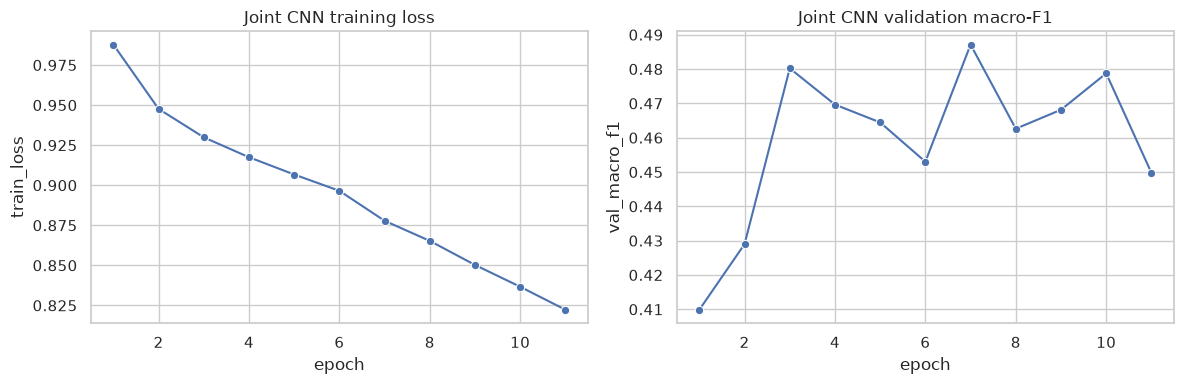

In [14]:
CNN_META_FEATURES = PREMATCH_FEATURES + ["ply"]
cnn_scaler = StandardScaler()
cnn_meta = snapshots[CNN_META_FEATURES].to_numpy(dtype=np.float32)
cnn_meta[snapshot_masks["train"]] = cnn_scaler.fit_transform(cnn_meta[snapshot_masks["train"]])
cnn_meta[snapshot_masks["validation"]] = cnn_scaler.transform(cnn_meta[snapshot_masks["validation"]])
cnn_meta[snapshot_masks["test"]] = cnn_scaler.transform(cnn_meta[snapshot_masks["test"]])


class SnapshotDataset(Dataset):
    def __init__(self, board_array, metadata_array, target_array, weight_array, mask):
        self.board_array = board_array
        self.metadata_array = metadata_array
        self.target_array = target_array.astype(np.int64)
        self.weight_array = weight_array.astype(np.float32)
        self.indices = np.flatnonzero(mask)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        index = self.indices[item]
        return (
            torch.from_numpy(self.board_array[index].astype(np.float32)),
            torch.from_numpy(self.metadata_array[index]),
            torch.tensor(self.target_array[index], dtype=torch.long),
            torch.tensor(self.weight_array[index], dtype=torch.float32),
        )


class JointCNN(nn.Module):
    def __init__(self, metadata_size: int):
        super().__init__()
        self.board_encoder = nn.Sequential(
            nn.Conv2d(17, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 + metadata_size, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(64, 3),
        )

    def forward(self, board_input, metadata_input):
        board_embedding = self.board_encoder(board_input).flatten(1)
        return self.classifier(torch.cat([board_embedding, metadata_input], dim=1))


def predict_cnn(model: nn.Module, loader: DataLoader) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    probabilities, targets = [], []
    with torch.no_grad():
        for board_batch, metadata_batch, target_batch, _ in loader:
            logits = model(board_batch.to(DEVICE), metadata_batch.to(DEVICE))
            probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
            targets.append(target_batch.numpy())
    return np.concatenate(probabilities), np.concatenate(targets)


train_dataset = SnapshotDataset(boards, cnn_meta, y_snapshot, snapshot_weights, snapshot_masks["train"])
val_dataset = SnapshotDataset(boards, cnn_meta, y_snapshot, np.ones(len(snapshots)), snapshot_masks["validation"])
test_dataset = SnapshotDataset(boards, cnn_meta, y_snapshot, np.ones(len(snapshots)), snapshot_masks["test"])
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0, generator=generator)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False, num_workers=0)

cnn = JointCNN(len(CNN_META_FEATURES)).to(DEVICE)
criterion = nn.CrossEntropyLoss(reduction="none")
optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-4)

best_state, best_val_f1 = None, -np.inf
patience, epochs_without_improvement, history = 4, 0, []
for epoch in range(1, 21):
    cnn.train()
    running_loss, running_weight = 0.0, 0.0
    for board_batch, metadata_batch, target_batch, sample_weight_batch in train_loader:
        optimizer.zero_grad(set_to_none=True)
        logits = cnn(board_batch.to(DEVICE), metadata_batch.to(DEVICE))
        losses = criterion(logits, target_batch.to(DEVICE))
        weights = sample_weight_batch.to(DEVICE)
        loss = (losses * weights).sum() / weights.sum()
        loss.backward()
        optimizer.step()
        running_loss += (losses.detach() * weights).sum().item()
        running_weight += weights.sum().item()

    val_proba_epoch, val_targets_epoch = predict_cnn(cnn, val_loader)
    val_f1_epoch = f1_score(val_targets_epoch, val_proba_epoch.argmax(axis=1), average="macro", zero_division=0)
    history.append({"epoch": epoch, "train_loss": running_loss / running_weight, "val_macro_f1": val_f1_epoch})
    print(f"Epoch {epoch:02d} | train loss {history[-1]['train_loss']:.4f} | val macro-F1 {val_f1_epoch:.4f}")
    if val_f1_epoch > best_val_f1 + 1e-4:
        best_val_f1 = val_f1_epoch
        best_state = {key: value.detach().cpu().clone() for key, value in cnn.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break

cnn.load_state_dict(best_state)
cnn.to(DEVICE)
cnn_val_proba, cnn_val_targets = predict_cnn(cnn, val_loader)
cnn_test_proba, cnn_test_targets = predict_cnn(cnn, test_loader)
display(pd.DataFrame([
    metric_row("Joint CNN (validation)", cnn_val_targets, cnn_val_proba),
    metric_row("Joint CNN (test)", cnn_test_targets, cnn_test_proba),
]).style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

history_frame = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=history_frame, x="epoch", y="train_loss", marker="o", ax=axes[0])
sns.lineplot(data=history_frame, x="epoch", y="val_macro_f1", marker="o", ax=axes[1])
axes[0].set_title("Joint CNN training loss")
axes[1].set_title("Joint CNN validation macro-F1")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "05_cnn_training_history.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Model comparison and progressive evaluation

Validation macro-F1 selects between the Stockfish-assisted joint tabular model and the joint CNN. The selected model is then used directly for the final test curve.

In [15]:
validation_comparison = pd.DataFrame([
    metric_row(best_tabular_name, y_snapshot[snapshot_masks["validation"]], tabular_val_probas[best_tabular_name]),
    metric_row("Joint CNN", cnn_val_targets, cnn_val_proba),
]).sort_values("macro_f1", ascending=False)
display(validation_comparison.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}"}))

selected_in_game_name = validation_comparison.iloc[0]["model"]
if selected_in_game_name == "Joint CNN":
    final_test_proba = cnn_test_proba
else:
    final_test_proba = tabular_test_probas[best_tabular_name]
print(f"Selected in-game model: {selected_in_game_name}")

,model,accuracy,macro_f1,log_loss
0,Joint metadata + manual + Stockfish,0.651,0.524,0.788
1,Joint CNN,0.591,0.487,0.888


Selected in-game model: Joint metadata + manual + Stockfish


In [16]:
test_comparison = []
for name in TABULAR_SPECS:
    test_comparison.append(metric_row(
        name,
        y_snapshot[snapshot_masks["test"]],
        tabular_test_probas[name],
    ))
test_comparison.append(metric_row("Joint CNN", cnn_test_targets, cnn_test_proba))
display(pd.DataFrame(test_comparison).sort_values("macro_f1", ascending=False).style.format({
    "accuracy": "{:.3f}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}",
}))

,model,accuracy,macro_f1,log_loss
1,Joint metadata + manual + Stockfish,0.687,0.545,0.714
0,Joint metadata + manual,0.639,0.488,0.797
2,Joint CNN,0.610,0.478,0.898


,progress_pct,accuracy,macro_f1,n
0,0,0.523,0.427,2867
1,10,0.584,0.435,2803
2,25,0.588,0.450,2830
3,50,0.649,0.498,2849
4,75,0.714,0.570,2830
5,100,0.899,0.779,2867


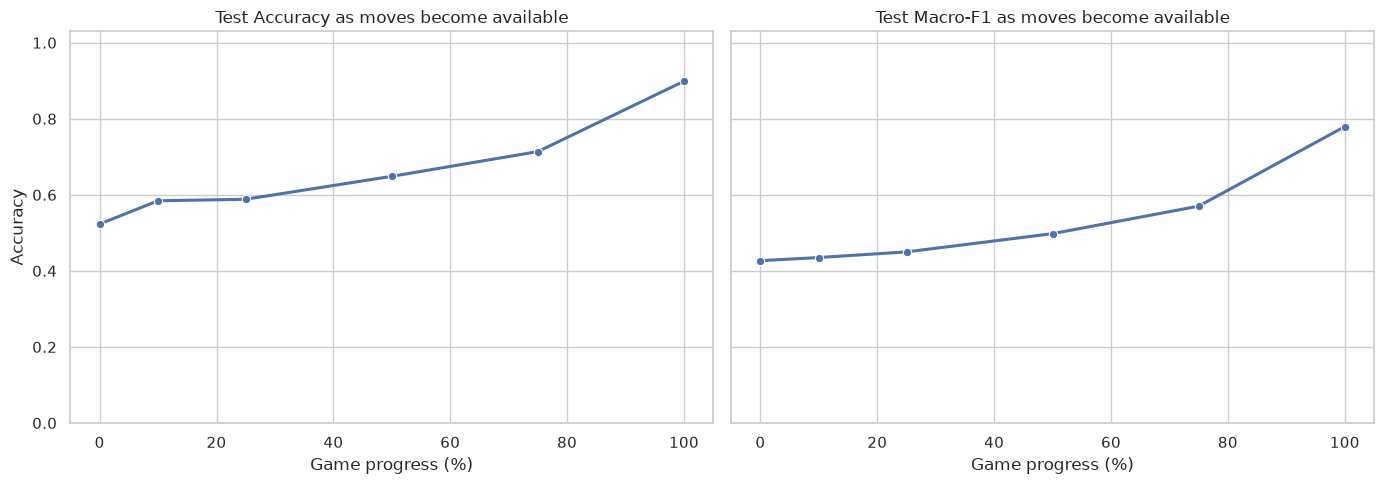

,area_under_accuracy_progress_curve,area_under_macro_f1_progress_curve
0,0.670,0.530


In [17]:
test_snapshots = snapshots.loc[snapshot_masks["test"]].reset_index(drop=True)

curve_rows = []

# The 0% point is evaluated once per test game using the selected pre-match model.
curve_rows.append({
    "progress_pct": 0,
    "accuracy": accuracy_score(y_test, prematch_test_proba.argmax(axis=1)),
    "macro_f1": f1_score(y_test, prematch_test_proba.argmax(axis=1), average="macro", zero_division=0),
    "n": len(y_test),
})

for checkpoint in EVALUATION_FRACTIONS:
    mask = test_snapshots["checkpoint"].eq(checkpoint).to_numpy()
    targets = test_snapshots.loc[mask, "target"].to_numpy()
    predictions = final_test_proba[mask].argmax(axis=1)
    curve_rows.append({
        "progress_pct": int(checkpoint * 100),
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(targets, predictions, average="macro", zero_division=0),
        "n": len(targets),
    })

model_curve = pd.DataFrame(curve_rows).sort_values("progress_pct")
display(model_curve.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for axis, metric, title in zip(axes, ["accuracy", "macro_f1"], ["Accuracy", "Macro-F1"]):
    sns.lineplot(data=model_curve, x="progress_pct", y=metric, marker="o", linewidth=2.2, ax=axis)
    axis.set_ylim(0, 1.03)
    axis.set_xlabel("Game progress (%)")
    axis.set_ylabel(title)
    axis.set_title(f"Test {title} as moves become available")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "06_progressive_performance_curve.png", dpi=300, bbox_inches="tight")
plt.show()

progress_axis = model_curve["progress_pct"].to_numpy() / 100
curve_summary = pd.DataFrame([{
    "area_under_accuracy_progress_curve": np.trapezoid(model_curve["accuracy"], x=progress_axis),
    "area_under_macro_f1_progress_curve": np.trapezoid(model_curve["macro_f1"], x=progress_axis),
}])
display(curve_summary.style.format({
    "area_under_accuracy_progress_curve": "{:.3f}",
    "area_under_macro_f1_progress_curve": "{:.3f}",
}))

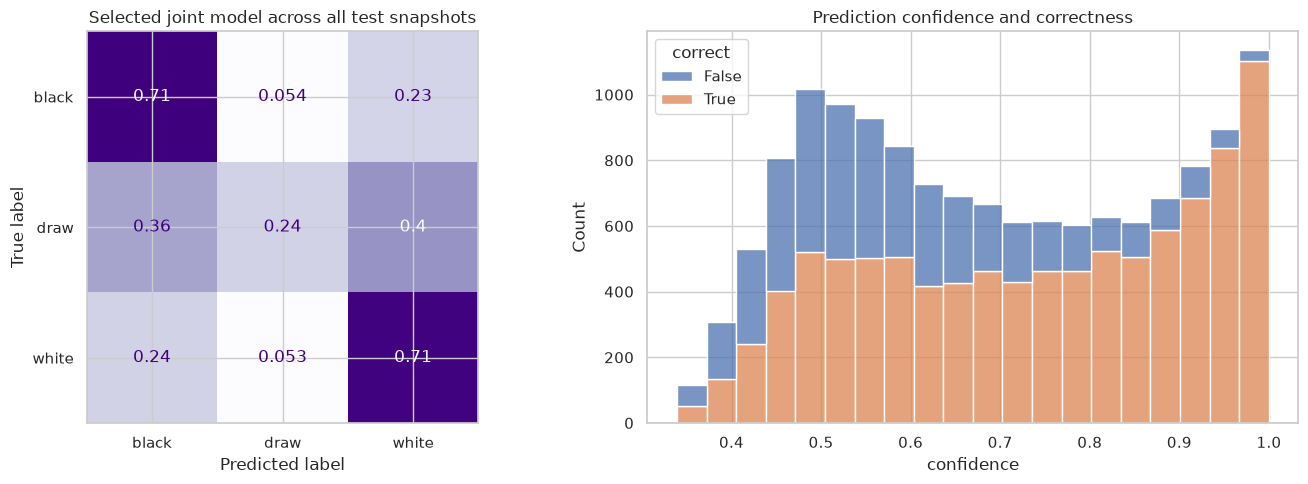

              precision    recall  f1-score   support

       black      0.704     0.712     0.708      6447
        draw      0.180     0.240     0.206       663
       white      0.738     0.707     0.722      7069

    accuracy                          0.687     14179
   macro avg      0.541     0.553     0.545     14179
weighted avg      0.696     0.687     0.692     14179



In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(
    test_snapshots["target"],
    final_test_proba.argmax(axis=1),
    display_labels=CLASS_NAMES,
    normalize="true",
    cmap="Purples",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Selected joint model across all test snapshots")

confidence = final_test_proba.max(axis=1)
correct = final_test_proba.argmax(axis=1) == test_snapshots["target"].to_numpy()
confidence_frame = pd.DataFrame({"confidence": confidence, "correct": correct})
sns.histplot(data=confidence_frame, x="confidence", hue="correct", bins=20, multiple="stack", ax=axes[1])
axes[1].set_title("Prediction confidence and correctness")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "07_final_confusion_confidence.png", dpi=300, bbox_inches="tight")
plt.show()

print(classification_report(
    test_snapshots["target"],
    final_test_proba.argmax(axis=1),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

## 8. Conclusions, limitations, and responsible interpretation

The executed tables support four direct conclusions:

1. **Pre-match signal:** rating and time-control information provide a useful but limited starting prediction.
2. **Joint tabular model:** Stockfish adds a compact, strong description of the current position while the pre-match variables allow the model to adapt objective engine information to the human players and time control.
3. **CNN comparison:** the CNN tests end-to-end spatial learning under the same joint-information principle, but uses only game-result supervision—no Stockfish labels, policy learning, self-play, or reinforcement learning.
4. **Progressive evaluation:** the selected joint model is evaluated directly at retrospective percentage checkpoints. The endpoint remains a prediction and is not replaced with the known result.

### Limitations

- Stockfish uses a deliberately small 1,000-node budget; deeper analysis could improve feature quality at much greater computational cost.
- WDL describes engine self-play rather than rating- and time-specific human behaviour, although joint training is intended to correct part of this mismatch.
- The dataset has no per-move clock, so timeout pressure cannot be modelled directly.
- Random game-level splitting does not test temporal drift or completely unseen player populations.
- Percentage checkpoints use final length only to locate retrospective test positions; deployed inference uses current ply.

### Generative AI use declaration

OpenAI Codex was used to assist with structuring the analysis, drafting Python code, debugging, and language editing for the notebook, report, and README. The project authors reviewed and validated all generated content, methodological decisions, code execution, numerical results, references, and interpretations, and retain full responsibility for the submitted work. No generative-AI-produced observations, outcomes, or labels were added to the dataset.